# White Dwarf Classification (No Data Leakage)

Rare-object detection: classify white dwarfs against the broader stellar population.

**Label source:** spectroscopically confirmed classifications (`spec_class`), independent of
H-R diagram position. This breaks the circularity of the photometric `Pwd` catalogue, where
white dwarf membership is *defined* by colour and absolute magnitude (the same quantities used
as features).

**Datasets:**
1. `gaiaedr3_wd_sdssspec.csv` - Gaia x SDSS spectroscopic sample. Provides spectroscopically
   confirmed white dwarfs (positives) and confirmed contaminants (STAR, QSO, GALAXY, CV; negatives).
2. `gaia_1kpc.csv` - uniform random subsample (via `random_index`) of Gaia DR3 stars within 1 kpc
   with parallax/error >= 5. Provides field-star negatives to restore a realistic rare-detection
   class balance.
3. `gaiaedr3_wd_main.csv` - full Gentile Fusillo EDR3 catalogue of 1.28M white dwarf candidates.
   Used ONLY to clean likely white dwarfs (`Pwd > 0.75`) out of the field-star negatives, never as
   a feature.

**Selection matching:** the field stars come from a Gaia query with parallax and photometric
quality cuts. The same cuts are applied to the spectroscopic sample, so that distance and apparent
brightness can't reveal which catalogue an object came from.

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    precision_score, recall_score, balanced_accuracy_score, matthews_corrcoef,
    PrecisionRecallDisplay, RocCurveDisplay, ConfusionMatrixDisplay,
)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

## 1. Read in the data

In [18]:
from pathlib import Path

DATA_DIR = Path("../data")   # see data/white_dwarf_data_notes.txt for where each file comes from

wd_df = pd.read_csv(DATA_DIR / "gaiaedr3_wd_sdssspec.csv")
gaia_df = pd.read_csv(DATA_DIR / "gaia_1kpc.csv")
wd_cat = pd.read_csv(DATA_DIR / "gaiaedr3_wd_main.csv", usecols=["source_id", "Pwd"])   # only used to clean negatives

print(f"Spectroscopic DF shape: {wd_df.shape}")
print(f"Field-star Gaia DF shape: {gaia_df.shape}")
print(f"Gentile Fusillo WD catalogue shape: {wd_cat.shape}")

ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

## 2. Build binary labels from spectroscopic classes

White dwarf spectral types -> 1. Spectroscopically confirmed contaminants -> 0.
Everything else is dropped: unreliable/unknown spectra, and WD+main-sequence binaries (blended
photometry, ambiguous membership). Classes are matched explicitly on both sides, so an unlisted
class can't silently fall into the negatives.

Some objects have several SDSS spectra. Objects whose spectra disagree on the label are dropped,
and the rest keep only their highest-S/N spectrum, so the same star can't land in both the training
and the test set.

In [ ]:
wd_classes = {
    'DA', 'DA:', 'DAB', 'DABZ', 'DAH', 'DAO', 'DAZ', 'DA_DQ', 'DApec',
    'DB', 'DB:', 'DBA', 'DBAH', 'DBH', 'DBZ', 'DBAZ',
    'DC', 'DC:', 'DO', 'DOX', 'DQ', 'DQ:', 'DQZ', 'pecDQ', 'hotDQ',
    'DZ', 'DZ:', 'DZA', 'DZAB', 'DZB', 'DZBA', 'DZH',
    'WD', 'WDpec', 'MWD', 'PG1159'
}
contaminant_classes = {'STAR', 'QSO', 'GALAXY', 'CV'}
# Everything else is dropped, e.g. UNKN, Unreli, DA_MS, DA_MS:, DC_MS, DB_MS

In [ ]:
# FITS string columns are space-padded - strip before matching or .isin() silently fails
wd_df['spec_class'] = wd_df['spec_class'].str.strip()

# Drop unreliable / unknown / blended-binary spectra (anything not in either list)
unlabelled = ~wd_df['spec_class'].isin(wd_classes | contaminant_classes)
print("Dropped spectral classes:", wd_df.loc[unlabelled, 'spec_class'].value_counts().to_dict())
wd_df = wd_df[~unlabelled].copy()

# Binary label: 1 = white dwarf, 0 = confirmed contaminant
wd_df['class'] = wd_df['spec_class'].isin(wd_classes).astype(int)

# One row per object: drop objects whose spectra disagree, keep the highest-S/N spectrum
n_labels = wd_df.groupby('source_id')['class'].transform('nunique')
print(f"Objects with conflicting labels across spectra (dropped): {wd_df.loc[n_labels > 1, 'source_id'].nunique()}")
before = len(wd_df)
wd_df = (wd_df[n_labels == 1]
         .sort_values('S/N', ascending=False)
         .drop_duplicates('source_id')
         .copy())
print(f"Rows: {before} spectra -> {len(wd_df)} unique objects")

print()
print(wd_df['class'].value_counts())
print()
print("Confirmed contaminants in this sample:")
print(wd_df.loc[wd_df['class'] == 0, 'spec_class'].value_counts())

Dropped spectral classes: {'Unreli': 1425, 'DA_MS': 988, 'DB_MS': 41, 'UNKN': 35, 'DC_MS': 34, 'DA_MS:': 4}
Objects with conflicting labels across spectra (dropped): 62
Rows: 39480 spectra -> 30383 unique objects

class
1    25620
0     4763
Name: count, dtype: int64

Confirmed contaminants in this sample:
spec_class
STAR      4499
CV         225
QSO         26
GALAXY      13
Name: count, dtype: int64


## 2b. Apply the field-star selection cuts

The field-star negatives come from a Gaia DR3 query (v2, see the README) with `parallax >= 1`
(within 1 kpc), `parallax_over_error >= 5`, photometric signal-to-noise cuts (G >= 50, BP and
RP >= 10) and `phot_g_mean_mag < 20.7`. The spectroscopic sample has no such cuts. Left as is,
`parallax` and apparent brightness would reveal which catalogue an object came from rather than
what it is - a selection-function leak.

Applying the same cuts puts both classes in the same region of parameter space. Flux
signal-to-noise is recovered from the magnitude errors: `flux_over_error = 2.5 / ln(10) / mag_error`.

The first version of the query (v1: within 400 pc, 5% parallax precision) kept only 27% of the
spectroscopic white dwarfs and 1% of the contaminants. Most SDSS white dwarfs are too faint to have
5%-precise parallaxes, and most contaminants are too distant. The looser v2 cuts keep far more of
both, at the cost of noisier absolute magnitudes.

In [ ]:
k = 2.5 / np.log(10)   # converts a magnitude error to flux signal-to-noise
selection = (
    (wd_df['parallax'] >= 1)
    & (wd_df['parallax'] / wd_df['parallax_error'] >= 5)
    & (k / wd_df['phot_g_mean_mag_error'] >= 50)
    & (k / wd_df['phot_bp_mean_mag_error'] >= 10)
    & (k / wd_df['phot_rp_mean_mag_error'] >= 10)
    & (wd_df['phot_g_mean_mag'] < 20.7)
)
print("Passing the field-star cuts (columns), by class (rows):")
print(pd.crosstab(wd_df['class'], selection))

wd_df = wd_df[selection].copy()
print()
print(wd_df['class'].value_counts())
print("Remaining contaminants:", wd_df.loc[wd_df['class'] == 0, 'spec_class'].value_counts().to_dict())

Passing the field-star cuts (columns), by class (rows):
col_0  False  True 
class              
0       4539    224
1       7826  17794

class
1    17794
0      224
Name: count, dtype: int64
Remaining contaminants: {'CV': 129, 'STAR': 90, 'GALAXY': 3, 'QSO': 2}


## 3. Engineer features (spectroscopic sample)

Only observational quantities derived from Gaia photometry and astrometry. The atmospheric
parameters (`teff_*`, `logg_*`, `mass_*`) and the photometric probabilities (`Pwd`, `PHwd`) are
**deliberately excluded** - they are derived assuming the object is a white dwarf and would leak
the label.

Note: there is no `pmra`/`pmdec` in this file, so a true total proper motion cannot be computed
here. `sqrt(ra**2 + dec**2)` is NOT proper motion (it is angular distance from the coordinate
origin) and must not be used.

In [ ]:
wd_df['g_mag_abs'] = wd_df['phot_g_mean_mag'] - 5 * np.log10(1000 / wd_df['parallax']) + 5
wd_df['bp_rp'] = wd_df['phot_bp_mean_mag'] - wd_df['phot_rp_mean_mag']
wd_df['g_rp'] = wd_df['phot_g_mean_mag'] - wd_df['phot_rp_mean_mag']

### Quick look: H-R diagram of the spectroscopic sample

With spectroscopic labels, white dwarfs (class 1) occupy the lower-left region but the separation
is no longer circular - the labels came from spectra, not from this position.

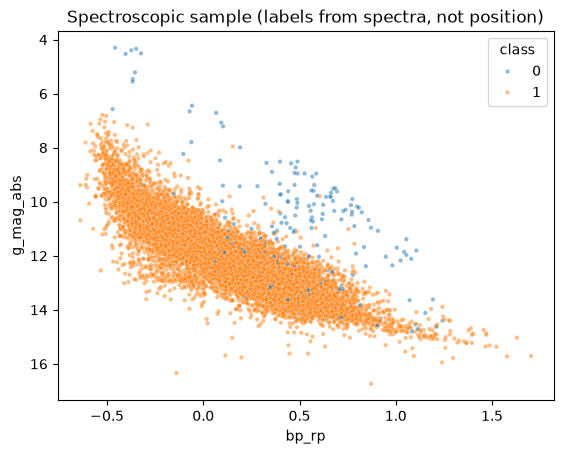

In [ ]:
ax = sns.scatterplot(data=wd_df, x="bp_rp", y="g_mag_abs", hue="class", alpha=0.5, s=10)
ax.invert_yaxis()
ax.set_title("Spectroscopic sample (labels from spectra, not position)")
plt.show()

## 4. Reduce the spectroscopic catalogue to modelling columns

Keep identifiers (for joining/dedup), the label, the spectral class (for error analysis only, never a
feature) and the observational features. Drop everything WD-model-derived.

The feature set is deliberately small. Absolute magnitudes and colours are exact functions of the
apparent magnitudes and parallax (`bp_rp = BP - RP`, `M_G = G + 5 log10(parallax) - 10`), so a
longer list such as `bp_mag_abs`, `rp_mag_abs`, `phot_bp_mean_mag`, `phot_rp_mean_mag` adds no
information. Duplicates only split importance between them, which could hide a dominant feature in
the leakage check of section 14. The four features below are independent and together carry exactly
the information in G, BP, RP and parallax.

In [ ]:
# Common feature set shared with the field-star negatives below.
feature_cols = ['g_mag_abs', 'bp_rp', 'g_rp', 'parallax']

keep_cols = ['source_id', 'dr2_source_id', 'spec_class', 'class'] + feature_cols
wd_model = wd_df[keep_cols].copy()
wd_model.head()

,source_id,dr2_source_id,spec_class,class,g_mag_abs,bp_rp,g_rp,parallax
29454,1353169686155129344,1.353170e+18,DA,1,9.482107,-0.473293,-0.321592,5.399857
24808,4465105351622152704,4.465105e+18,DA,1,10.951400,-0.212889,-0.151625,12.087025
35025,579931846088268928,5.799318e+17,DA,1,10.809943,-0.227097,-0.162434,8.413305
21141,3875967741350019456,3.875968e+18,DA,1,10.904111,-0.201313,-0.146353,6.191029
41502,1198632983274798336,1.198633e+18,DA,1,11.238680,-0.136508,-0.104768,12.612918


## 5. Add field-star negatives from the broad Gaia pull

This restores a realistic rare-detection balance. Two safeguards prevent white dwarfs leaking
into the negative class:

1. **Dedup against the spectroscopic positives** - drop any `source_id` already labelled here.
2. **Clean against the Gentile Fusillo WD catalogue** - drop any field star that is a
   high-confidence white dwarf candidate (`Pwd > 0.75`, the catalogue's recommended cut). Low-`Pwd`
   candidates are kept: they sit near the white dwarf sequence without being white dwarfs, so they
   are exactly the hard negatives the model needs to see. Using `Pwd` to *clean negatives* is fine;
   it is not fed to the model, so it does not reintroduce leakage.

Residual contamination (faint/distant white dwarfs missed by both catalogues) is small (<~1%) and
sets a soft ceiling on achievable precision.

**ID-release caution:** the spectroscopic file carries both `source_id` (EDR3/DR3) and
`dr2_source_id`. Match each cross-check on the release the field-star pull actually uses. The block
below assumes the field-star pull is DR3-keyed (`source_id`); adjust if yours is DR2.

In [ ]:
# --- engineer the SAME features on the field-star pull ---
g = gaia_df.copy()

g['bp_rp'] = g['phot_bp_mean_mag'] - g['phot_rp_mean_mag']
g['g_mag_abs'] = g['phot_g_mean_mag'] - 5 * np.log10(1000 / g['parallax']) + 5
g['g_rp'] = g['phot_g_mean_mag'] - g['phot_rp_mean_mag']

# --- safeguard 1: remove spectroscopic positives from the field stars ---
pos_ids = set(wd_model['source_id'])
before = len(g)
g = g[~g['source_id'].isin(pos_ids)]
print(f"Removed {before - len(g)} rows already in the spectroscopic sample.")

# --- safeguard 2: remove high-confidence WD candidates (Gentile Fusillo catalogue) ---
known_wd_ids = set(wd_cat.loc[wd_cat['Pwd'] > 0.75, 'source_id'])
print(f"High-confidence catalogue white dwarfs (Pwd > 0.75): {len(known_wd_ids):,}")
before = len(g)
g = g[~g['source_id'].isin(known_wd_ids)]
print(f"Removed {before - len(g)} field stars matching the full WD catalogue.")

# --- label as negatives and align to the shared schema ---
g['class'] = 0
g['spec_class'] = 'FIELD'   # marks field stars apart from spectroscopic contaminants
if 'dr2_source_id' not in g.columns:
    g['dr2_source_id'] = np.nan
g_neg = g[keep_cols].copy()

# --- combine ---
data = pd.concat([wd_model, g_neg], ignore_index=True)

print()
print("Combined class balance:")
print(data['class'].value_counts())
print((100 * data['class'].value_counts() / len(data)).round(2))

Removed 167 rows already in the spectroscopic sample.
High-confidence catalogue white dwarfs (Pwd > 0.75): 359,073
Removed 1974 field stars matching the full WD catalogue.

Combined class balance:
class
0    572314
1     17794
Name: count, dtype: int64
class
0    96.98
1     3.02
Name: count, dtype: float64


## 6. Handle missing values and inspect

Absolute magnitudes require a positive parallax; negative or zero parallaxes produce NaN/inf in
the log. Drop rows with missing engineered features before modelling.

In [ ]:
# Replace any inf from bad parallaxes, then drop rows missing features
data = data.replace([np.inf, -np.inf], np.nan)
print("Nulls per feature before drop:")
print(data[feature_cols].isna().sum())

data = data.dropna(subset=feature_cols).reset_index(drop=True)
print(f"\nRows after dropping incomplete feature rows: {len(data)}")
print(data['class'].value_counts())

Nulls per feature before drop:
g_mag_abs    0
bp_rp        0
g_rp         0
parallax     0
dtype: int64

Rows after dropping incomplete feature rows: 590108
class
0    572314
1     17794
Name: count, dtype: int64


### H-R diagram of the combined dataset

Negatives as a log-density map, white dwarfs drawn on top so the rare class stays visible.

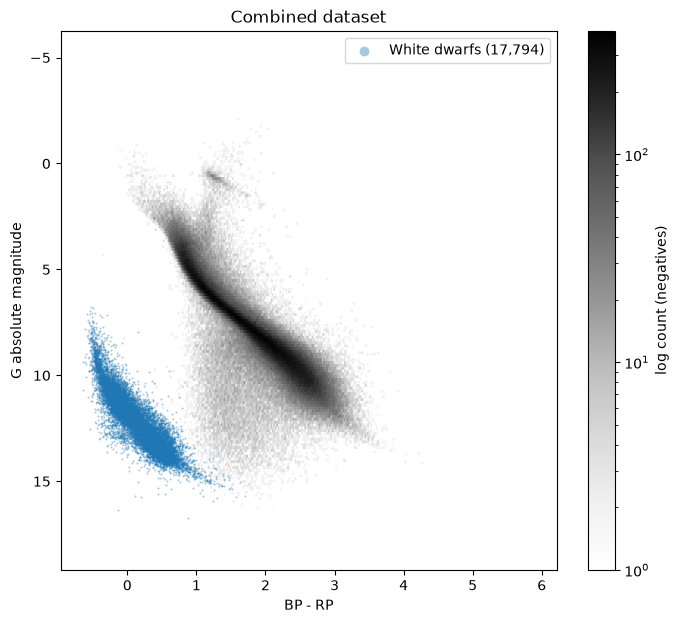

In [ ]:
negatives = data[data['class'] == 0]
wds = data[data['class'] == 1]

fig, ax = plt.subplots(figsize=(8, 7))
hb = ax.hexbin(negatives['bp_rp'], negatives['g_mag_abs'], gridsize=300, cmap='Greys',
               bins='log', mincnt=1)
ax.scatter(wds['bp_rp'], wds['g_mag_abs'], s=2, c='tab:blue', alpha=0.4, linewidth=0,
           label=f'White dwarfs ({len(wds):,})')
ax.invert_yaxis()
ax.set_xlabel("BP - RP")
ax.set_ylabel("G absolute magnitude")
ax.set_title("Combined dataset")
fig.colorbar(hb, label="log count (negatives)")
ax.legend(markerscale=5, loc="upper right")
plt.show()

## 7. Correlation check

Feature correlations and each feature's correlation with the (now leak-free) label.

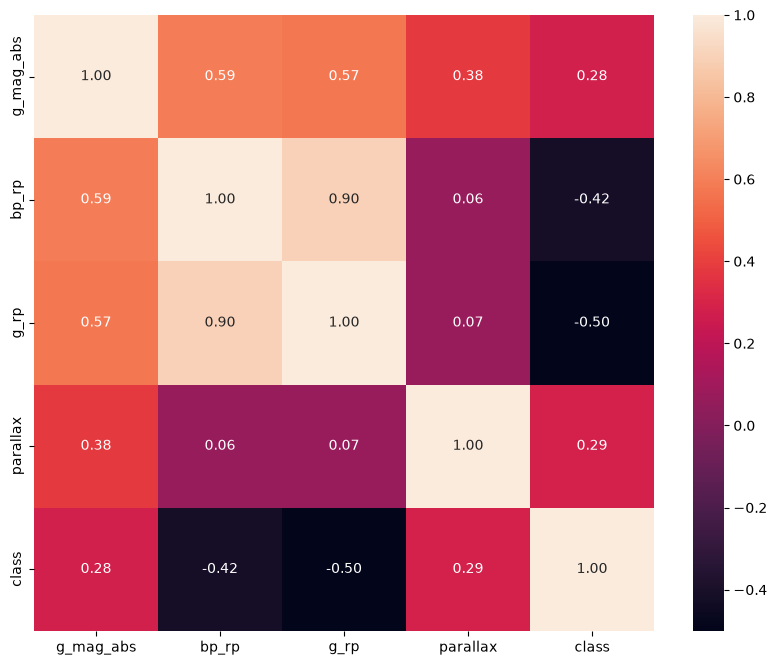

class        1.000000
parallax     0.287003
g_mag_abs    0.282216
bp_rp       -0.418430
g_rp        -0.500530
Name: class, dtype: float64

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(data[feature_cols + ['class']].corr(numeric_only=True), annot=True, fmt=".2f")
plt.show()

data[feature_cols + ['class']].corr(numeric_only=True)['class'].sort_values(ascending=False)

## 8. Train/test split FIRST, then balance only the training set

Critical ordering for a rare-detection problem:

- Split first, `stratify` to keep white dwarfs present on both sides.
- **The test set keeps the dataset's imbalance** (no resampling), so metrics aren't inflated by an
  artificially balanced test set. The field stars are a random subsample, so the exact prevalence is
  set by the query's sampling fraction rather than by the true sky density.
- Undersample the majority **only in the training set**.
- Fit the scaler on the (balanced) training set, transform the test set.

In [ ]:
X = data[feature_cols]
y = data['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# --- undersample the majority in the TRAINING set only ---
train = pd.concat([X_train, y_train], axis=1)
minority = train[train['class'] == 1]
majority = train[train['class'] == 0]

# majority:minority ratio (adjust as needed; 1:1 is usually too aggressive)
n_major = min(len(majority), len(minority) * 10)
majority_sampled = majority.sample(n=n_major, random_state=42)

train_bal = pd.concat([minority, majority_sampled]).sample(frac=1, random_state=42)
X_train = train_bal[feature_cols]
y_train = train_bal['class']

print("Training balance after undersampling:")
print(y_train.value_counts())
print("\nTest balance (not resampled):")
print(y_test.value_counts())

# --- scale (fit on train only) ---
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

Training balance after undersampling:
class
0    142350
1     14235
Name: count, dtype: int64

Test balance (not resampled):
class
0    114463
1      3559
Name: count, dtype: int64


# Modelling

## 9. Train

Four models, from linear to boosted trees. `class_weight='balanced'` (and `scale_pos_weight` for
XGBoost) compensates for the 10:1 imbalance that remains after undersampling.

Each model's test-set scores are kept for evaluation: `predict_proba` where available, otherwise
`decision_function` (LinearSVC). Only the ranking of the scores matters for PR and ROC curves.

In [ ]:
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

models_dict = {
          "LogReg": LogisticRegression(),
          "SVM": LinearSVC(),
          "RF": RandomForestClassifier(),
          "XGB": XGBClassifier(),
          }

params_dict = {
          "LogReg": {"penalty": "l1", "C": 1, "class_weight": "balanced", "random_state": 42069, "solver": "liblinear"},
          "SVM": {"C": 1, "class_weight": "balanced", "dual": "auto", "random_state": 42069},
          "RF": {"n_estimators": 100, "criterion": "gini", "class_weight": "balanced", "min_samples_leaf": 5, "random_state": 42069},
          "XGB": {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1, "tree_method": "hist",
                  "scale_pos_weight": scale_pos_weight, "random_state": 42069},
          }

fitted_models = {}
scores_dict = {}   # positive-class scores on the test set, per model

In [ ]:
for model in models_dict.keys():
    print(f"Starting on {model}")
    clf = models_dict[model]
    clf.set_params(**params_dict[model])
    clf.fit(X_train_s, y_train)

    # LinearSVC has no predict_proba; decision_function scores work for PR/ROC curves
    # since only the ranking matters
    if hasattr(clf, "predict_proba"):
        scores = clf.predict_proba(X_test_s)[:, 1]
    else:
        scores = clf.decision_function(X_test_s)

    fitted_models[model] = clf
    scores_dict[model] = scores

Starting on LogReg
Starting on SVM


c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Starting on RF
Starting on XGB


## 10. Precision-recall and ROC curves

PR-AUC is the headline metric for a rare positive class. The dashed line is a no-skill classifier,
whose precision equals the share of white dwarfs in the test set - read every PR-AUC against it.

ROC is shown for completeness. Under heavy imbalance it looks optimistic: the false-positive rate is
divided by a very large number of easy negatives.

c:\Users\Dhyey\anaconda3\envs\ml-ops\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


TypeError: RocCurveDisplay.from_predictions() got an unexpected keyword argument 'label'

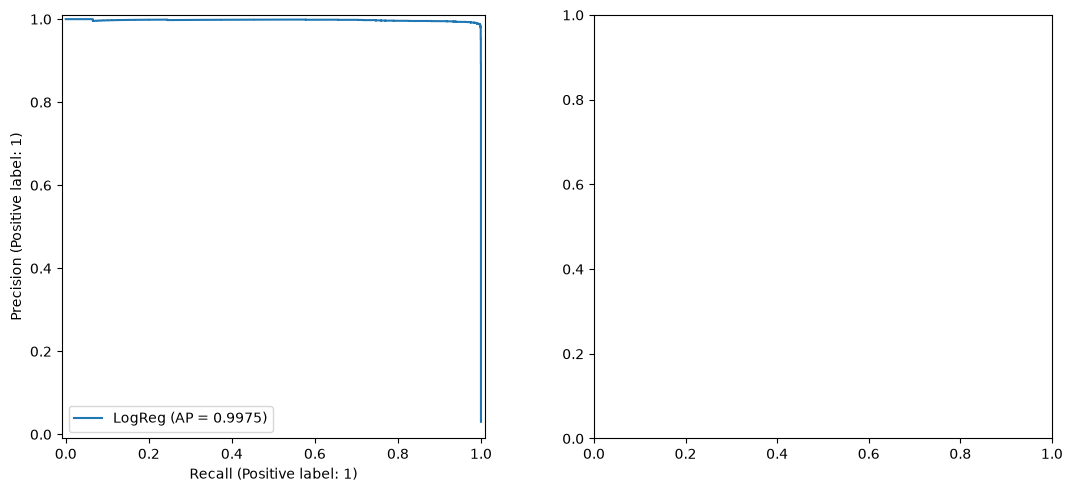

In [ ]:
prevalence = y_test.mean()

fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(13, 5.5))
for name, scores in scores_dict.items():
    # explicit labels: the default legend rounds to 2 decimals, which shows every model as 1.00
    PrecisionRecallDisplay.from_predictions(
        y_test, scores, ax=ax_pr, label=f"{name} (AP = {average_precision_score(y_test, scores):.4f})")
    RocCurveDisplay.from_predictions(
        y_test, scores, ax=ax_roc, label=f"{name} (AUC = {roc_auc_score(y_test, scores):.4f})")

ax_pr.axhline(prevalence, ls="--", c="k", label=f"No skill (AP = {prevalence:.4f})")
ax_pr.set_title("Precision-recall (test set, not resampled)")
ax_pr.legend(loc="lower left")

ax_roc.plot([0, 1], [0, 1], "k--", label="Chance")
ax_roc.set_title("ROC")
ax_roc.legend(loc="lower right")
plt.show()

## 11. Metrics at a tuned operating point

The default 0.5 cutoff is a poor choice here. The models were trained at 10:1 but the test set keeps
the dataset's more extreme imbalance, and class weighting pushes scores up again, so predicted
probabilities are inflated (see the calibration plot below).

Instead, each model gets its own threshold: the highest one that still recovers at least 99% of white
dwarfs. The PR curves above stay flat almost to full recall, so 99% costs little precision, and the
white dwarfs that are still missed are genuine hard cases rather than an artefact of a strict cutoff.

The threshold is chosen on the test set, so recall is fixed by construction and precision is
slightly optimistic; a separate validation split would remove that bias. Precision, MCC and balanced accuracy are reported at that threshold, plus the number of false
alarms per white dwarf found. Plain accuracy is left out: labelling everything "not a white dwarf"
would already score over 99%.

In [ ]:
target_recall = 0.99
y_true = y_test.to_numpy()


def operating_point(y_true, scores, target_recall):
    """Highest threshold that still reaches target_recall, and the predictions it gives."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    # precision/recall have one more element than thresholds; align by slicing
    idx = np.where(recall[:-1] >= target_recall)[0][-1]
    return thresholds[idx], scores >= thresholds[idx]


metrics_dict = {}
preds_dict = {}
for name, scores in scores_dict.items():
    threshold, preds = operating_point(y_true, scores, target_recall)
    tp = (preds & (y_true == 1)).sum()
    fp = (preds & (y_true == 0)).sum()

    preds_dict[name] = preds
    metrics_dict[name] = {
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "threshold": threshold,
        "precision": precision_score(y_true, preds),
        "recall": recall_score(y_true, preds),
        "mcc": matthews_corrcoef(y_true, preds),
        "balanced_accuracy": balanced_accuracy_score(y_true, preds),
        "false_pos_per_wd": fp / tp,
    }

results = pd.DataFrame(metrics_dict).T.sort_values("pr_auc", ascending=False)
best = results.index[0]

print(f"No-skill PR-AUC (test prevalence): {prevalence:.4f}")
print(f"Best model by PR-AUC: {best}")
results.round(4)

### Confusion matrix for the best model

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_true, preds_dict[best], display_labels=["Not WD", "WD"], values_format=",d", cmap="Blues",
)
plt.title(f"{best} at threshold {metrics_dict[best]['threshold']:.3f} (recall >= {target_recall:.0%})")
plt.show()

### Calibration

Points below the diagonal mean the model is over-confident: a score of 0.8 is right far less than
80% of the time. That is the expected effect of training on a rebalanced set, and the reason the
threshold is tuned rather than fixed at 0.5. LinearSVC is left out, as its scores are not
probabilities.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, clf in fitted_models.items():
    if hasattr(clf, "predict_proba"):
        CalibrationDisplay.from_predictions(y_true, scores_dict[name], n_bins=10, name=name, ax=ax)
ax.set_title("Calibration on the test set")
plt.show()

## 12. Hard negatives

Almost all test negatives are ordinary field stars, most of them far from the white dwarf sequence,
so they are easy to reject and dominate PR-AUC. The spectroscopically confirmed contaminants (CVs and
stars that SDSS targeted as white dwarf candidates) are the hard cases. Only a couple of hundred survive
the selection cuts, and a fifth of those land in the test set, so treat their numbers as indicative.

In [ ]:
test_meta = data.loc[X_test.index, ['spec_class', 'class']]
groups = {
    "field stars": (test_meta['spec_class'] == 'FIELD').to_numpy(),
    "spectroscopic contaminants": (test_meta['class'].eq(0) & test_meta['spec_class'].ne('FIELD')).to_numpy(),
}

# False alarms per group: counts rather than rates, since the field-star rate rounds to zero
pd.DataFrame({
    name: {f"false alarms: {g} (of {mask.sum():,})": int(preds[mask].sum()) for g, mask in groups.items()}
    for name, preds in preds_dict.items()
}).T

## 13. Where the best model goes wrong

Missed white dwarfs and false alarms on the H-R diagram, over the density of all test negatives.

In [ ]:
test_plot = data.loc[X_test.index].assign(pred=preds_dict[best])
neg = test_plot[test_plot['class'] == 0]
true_pos = test_plot[(test_plot['class'] == 1) & test_plot['pred']]
false_neg = test_plot[(test_plot['class'] == 1) & ~test_plot['pred']]
false_pos = test_plot[(test_plot['class'] == 0) & test_plot['pred']]

fig, ax = plt.subplots(figsize=(8, 7))
ax.hexbin(neg['bp_rp'], neg['g_mag_abs'], gridsize=200, cmap='Greys', bins='log', mincnt=1)
ax.scatter(true_pos['bp_rp'], true_pos['g_mag_abs'], s=3, c='tab:blue', alpha=0.3, linewidth=0,
           label=f'Found white dwarfs ({len(true_pos):,})')
ax.scatter(false_neg['bp_rp'], false_neg['g_mag_abs'], s=8, c='tab:red', linewidth=0,
           label=f'Missed white dwarfs ({len(false_neg):,})')
ax.scatter(false_pos['bp_rp'], false_pos['g_mag_abs'], s=8, c='tab:orange', linewidth=0,
           label=f'False alarms ({len(false_pos):,})')
ax.invert_yaxis()
ax.set_xlabel("BP - RP")
ax.set_ylabel("G absolute magnitude")
ax.set_title(f"{best}: errors at recall >= {target_recall:.0%}")
ax.legend(markerscale=3, loc="upper right")
plt.show()

### Recall by white dwarf spectral type

Subtypes are grouped by primary type (DAB -> DA, hotDQ -> DQ). WD, MWD, PG1159 and other rare labels
are grouped as "Other".

In [ ]:
def wd_type(spec_class):
    """Primary spectral type: DAB -> DA, hotDQ -> DQ; WD, MWD, PG1159 -> Other."""
    s = spec_class.replace('pec', '').replace('hot', '')
    return s[:2] if s.startswith('D') else 'Other'


wd_test = test_plot[test_plot['class'] == 1].copy()
wd_test['type'] = wd_test['spec_class'].map(wd_type)
wd_test.groupby('type')['pred'].agg(n='size', recall='mean').sort_values('n', ascending=False).round(3)

## 14. Feature importance (permutation, on the test set)

A single dominant feature would signal residual leakage. Permutation importance measures how much
PR-AUC drops when one feature is shuffled on held-out data. Unlike impurity-based importance, it
isn't biased toward continuous high-cardinality features and works for any model. It runs on a
stratified 100k-row subsample of the test set to keep the cost down.

In [ ]:
X_imp, _, y_imp, _ = train_test_split(
    X_test_s, y_test, train_size=100_000, stratify=y_test, random_state=42
)
result = permutation_importance(
    fitted_models[best], X_imp, y_imp, scoring="average_precision", n_repeats=5, random_state=42,
)

importances = pd.DataFrame(
    {"mean": result.importances_mean, "std": result.importances_std}, index=feature_cols
).sort_values("mean")

importances["mean"].plot(kind="barh", xerr=importances["std"])
plt.xlabel("Drop in PR-AUC when shuffled")
plt.title(f"Permutation importance ({best})")
plt.show()

importances.round(4)

## 15. Log runs to MLflow

Set `USE_MLFLOW = False` to skip this if no tracking server is running at `localhost:5000`.

In [ ]:
USE_MLFLOW = True

if USE_MLFLOW:
    import mlflow
    import mlflow.sklearn

    mlflow.set_tracking_uri("http://localhost:5000")
    mlflow.set_experiment("Gaia / White Dwarf Classification")

    for model in models_dict.keys():
        with mlflow.start_run(run_name=model):
            mlflow.log_params(params_dict[model])
            mlflow.log_param("target_recall", target_recall)
            mlflow.log_metrics({k: float(v) for k, v in metrics_dict[model].items()})
            mlflow.sklearn.log_model(fitted_models[model], name=model)